# Entrega Final Proyecto - Jefferson Andres Lipez Pinzon

Nota: Cometí un error y le di a Ejecutar todas accidentalmente, lo que eliminó las evidencias de la presentación de la Entrega 3 del proyecto, por lo que los resultados van a variar, en el github se encuentran alojados los notebook descargados con los resultados por lo que pueden corroborarse mirando esos notebook


Enlace diapositivas

https://canva.link/9v5v9h1wic42rg5

## Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D,GlobalAveragePooling2D,Dropout, Flatten, Dense, Input
from keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Model
import keras
import tensorflow as tf

In [2]:
import os
from google.colab import userdata

#os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
#os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')


In [3]:
pip install mtcnn[tensorflow]


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 11.9 MB/s  0:00:00


## Cargando el Dataset

In [4]:
# Crea un directorio para el dataset
!mkdir -p facial-age-data

# Cambia al directorio para descargar el dataset allí
%cd facial-age-data

# Descarga el dataset de Kaggle
!kaggle datasets download -d frabbisw/facial-age

# Descomprime el archivo
!unzip facial-age.zip

# Vuelve al directorio raíz de Colab
%cd /content


Se han truncado las últimas 5000 líneas del flujo de salida.
  inflating: face_age/face_age/024/7213.png  
  inflating: face_age/face_age/024/7342.png  
  inflating: face_age/face_age/024/7366.png  
  inflating: face_age/face_age/024/7406.png  
  inflating: face_age/face_age/024/7411.png  
  inflating: face_age/face_age/024/7497.png  
  inflating: face_age/face_age/024/7511.png  
  inflating: face_age/face_age/024/7520.png  
  inflating: face_age/face_age/024/7558.png  
  inflating: face_age/face_age/024/7600.png  
  inflating: face_age/face_age/024/7629.png  
  inflating: face_age/face_age/024/765.png  
  inflating: face_age/face_age/024/7691.png  
  inflating: face_age/face_age/024/7771.png  
  inflating: face_age/face_age/024/7782.png  
  inflating: face_age/face_age/024/7817.png  
  inflating: face_age/face_age/024/786.png  
  inflating: face_age/face_age/024/7955.png  
  inflating: face_age/face_age/024/8099.png  
  inflating: face_age/face_age/024/8196.png  
  inflating: face_age

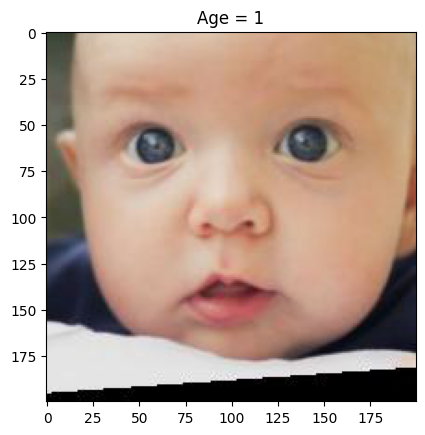

In [5]:
path = '/content/facial-age-data/face_age/face_age/'

#Ejemplo
img = mpimg.imread(path+'001/16.png')
plt.imshow(img)
plt.title('Age = 1')
plt.show()

In [7]:
import os
import pandas as pd

# Construir el DataFrame df_dataset antes de graficar su distribución
file_paths = []
ages = []

for folder, _, files in os.walk(path):
    if folder != "face_age":
        for file in files:
            file_paths.append(os.path.join(folder, file))
            ages.append(str(folder[-3:]))

df_dataset = pd.DataFrame({
    'filepath': file_paths,
    'age': pd.to_numeric(ages)
})

Total de imágenes en el dataset: 9778
Edad mínima: 1 años
Edad máxima: 110 años
Edad promedio: 29.41 años
Mediana de edad: 25.0 años


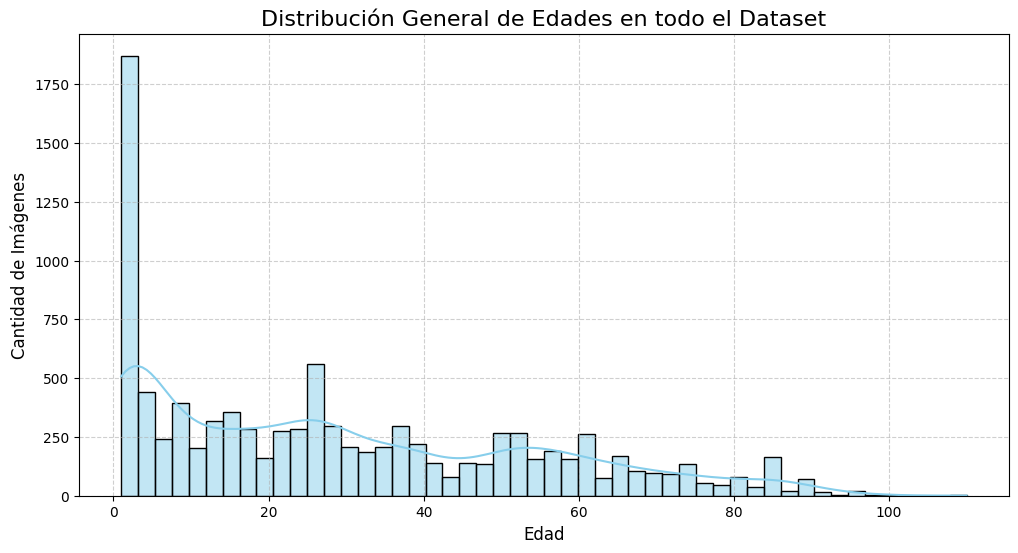

In [8]:
# Se revisa la distribución de edad del Dataset
# Configurar el tamaño de la gráfica
plt.figure(figsize=(12, 6))

# Graficar la distribución de edades en todo el dataset
sns.histplot(df_dataset['age'], bins=50, kde=True, color='skyblue')

plt.title('Distribución General de Edades en todo el Dataset', fontsize=16)
plt.xlabel('Edad', fontsize=12)
plt.ylabel('Cantidad de Imágenes', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

# Mostrar estadísticas básicas
print(f"Total de imágenes en el dataset: {len(df_dataset)}")
print(f"Edad mínima: {df_dataset['age'].min()} años")
print(f"Edad máxima: {df_dataset['age'].max()} años")
print(f"Edad promedio: {df_dataset['age'].mean():.2f} años")
print(f"Mediana de edad: {df_dataset['age'].median()} años")

plt.show()

## Obteniendo los datos de entrenamiento, validación y testeo

Debido a la cantidad de imagenes el entrenamiento del modelo daba problemas de RAM y se detenía para solucionarlo se uso ImageDataGenerator para que las imagenes se carguen en memoria y no en RAM

In [9]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 1. Creamos un DataFrame con las rutas de los archivos y sus respectivas edades (etiquetas)
file_paths = []
ages = []

for folder, _, files in os.walk(path):
    if folder != "face_age":
        for file in files:
            file_paths.append(os.path.join(folder, file))
            ages.append(str(folder[-3:]))  # Mantener como string o float según el generador

df_dataset = pd.DataFrame({
    'filepath': file_paths,
    'age': pd.to_numeric(ages)
})

# Split de los datos: 70% entrenamiento, 15% validación, 15% prueba
train_df, temp_df = train_test_split(df_dataset, test_size=0.3, random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42)

# 2. Configurar el Generador de Datos (solo normalización)
datagen = ImageDataGenerator(rescale=1./255)

train_generator = datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='age',
    target_size=(224, 224),
    class_mode='raw',
    batch_size=32,
    shuffle=True
)

val_generator = datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='filepath',
    y_col='age',
    target_size=(224, 224),
    class_mode='raw',
    batch_size=32,
    shuffle=False
)

test_generator = datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='filepath',
    y_col='age',
    target_size=(224, 224),
    class_mode='raw',
    batch_size=32,
    shuffle=False
)

Found 6844 validated image filenames.
Found 1467 validated image filenames.
Found 1467 validated image filenames.


# Entrega 2:
Desarrollo del modelo ResNet propío, con su entrenamiento y resultados

Nota: Para revisar que todas las celdas  funcionen correctamente se volvieron a ejecutar, lo que podría cambiar el desempeño del modelo presentado en la entrega 2. El notebook de la entrega2 se encuentra en el github para mantener la integridad de los resultados entregados ahí

## Creación del modelo propio



In [10]:
import keras
from keras.layers import Add, Activation, BatchNormalization

def residual_block(input_tensor, filters, kernel_size=3):
    x = Conv2D(filters, kernel_size, padding='same')(input_tensor)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)

    x = Conv2D(filters, kernel_size, padding='same')(x)
    x = BatchNormalization()(x)

    shortcut = Conv2D(filters, (1, 1), padding='same')(input_tensor)
    shortcut = BatchNormalization()(shortcut)

    x = Add()([x, shortcut])
    x = Activation('relu')(x)
    return x

def build_resnet_age_model(input_shape=(224, 224, 3)):
    inputs = Input(shape=input_shape)


    x = Conv2D(32, (3, 3), padding='same', activation='relu')(inputs)
    x = MaxPooling2D((2, 2))(x)

    x = residual_block(x, 64)
    x = MaxPooling2D((2, 2))(x)

    x = residual_block(x, 128)
    x = MaxPooling2D((2, 2))(x)

    x = residual_block(x, 256)
    x = GlobalAveragePooling2D()(x)

    x = Dense(128, activation='relu')(x)
    x = Dropout(0.4)(x)
    outputs = Dense(1, activation='linear')(x)

    model = keras.models.Model(inputs, outputs)
    return model

model = build_resnet_age_model()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 224, 224,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 112, 112,  │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 112, 112,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 112, 112,  │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 112, 112,  │     36,928 │ activation[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │      2,112 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 112, 112,  │          0 │ add[0][0]         │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 56, 56,    │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 56, 56,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        512 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 56, 56,    │    147,584 │ activation_2[0][

 Total params: 1,244,865 (4.75 MB)

 Trainable params: 1,242,177 (4.74 MB)

 Non-trainable params: 2,688 (10.50 KB)

## Compilación y Entrenamiento del Modelo

In [12]:
checkpointer = ModelCheckpoint(
    'modelface.keras',
    monitor='val_loss',
    mode='min',
    save_best_only=True,
    verbose=1
)

lr_reducer = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    verbose=1,
    restore_best_weights=True
)

model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mean_absolute_error'])

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=50,
    callbacks=[checkpointer, lr_reducer, early_stopping]
)

Epoch 1/50
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 288ms/step - loss: 638.3503 - mean_absolute_error: 19.7158
Epoch 1: val_loss improved from None to 1448.89368, saving model to modelface.keras

Epoch 1: finished saving model to modelface.keras
214/214 ━━━━━━━━━━━━━━━━━━━━ 120s 386ms/step - loss: 493.4405 - mean_absolute_error: 17.5933 - val_loss: 1448.8937 - val_mean_absolute_error: 32.2593 - learning_rate: 0.0010
Epoch 2/50
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - loss: 317.3345 - mean_absolute_error: 13.7755
Epoch 2: val_loss improved from 1448.89368 to 502.02625, saving model to modelface.keras

Epoch 2: finished saving model to modelface.keras
214/214 ━━━━━━━━━━━━━━━━━━━━ 64s 168ms/step - loss: 316.0651 - mean_absolute_error: 13.7344 - val_loss: 502.0262 - val_mean_absolute_error: 17.2508 - learning_rate: 0.0010
Epoch 3/50
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - loss: 276.3567 - mean_absolute_error: 12.5950
Epoch 3: val_loss improved from 502.02625 to 486.40320, saving model to m

### Visualización del Historial de Entrenamiento

Graficaremos la evolución de la pérdida (MSE) y del error absoluto medio (MAE) para analizar el comportamiento y la convergencia del modelo.

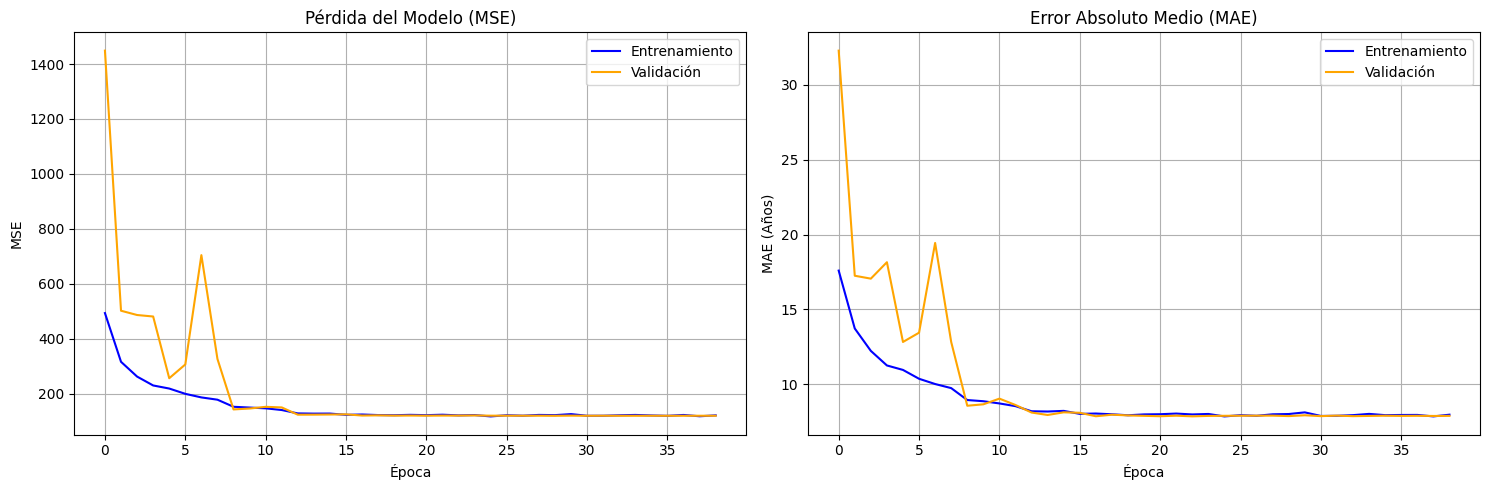

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico de Pérdida (MSE)
ax1.plot(history.history['loss'], label='Entrenamiento', color='blue')
ax1.plot(history.history['val_loss'], label='Validación', color='orange')
ax1.set_title('Pérdida del Modelo (MSE)')
ax1.set_xlabel('Época')
ax1.set_ylabel('MSE')
ax1.legend()
ax1.grid(True)

# Gráfico de MAE (Error Medio Absoluto)
ax2.plot(history.history['mean_absolute_error'], label='Entrenamiento', color='blue')
ax2.plot(history.history['val_mean_absolute_error'], label='Validación', color='orange')
ax2.set_title('Error Absoluto Medio (MAE)')
ax2.set_xlabel('Época')
ax2.set_ylabel('MAE (Años)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

## Evaluación con el Conjunto de Prueba
Evaluamos el modelo final con datos del conjunto de test para calcular los errores de predicción y obtener resultados.

In [14]:
# Evaluamos el modelo final con el test_generator
test_loss, test_mae = model.evaluate(test_generator)
print(f"Pérdida (MSE) en Test: {test_loss:.4f}")
print(f"Error Absoluto Medio (MAE) en Test: {round(test_mae, 1)} años")

46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 113ms/step - loss: 125.5706 - mean_absolute_error: 7.7925
Pérdida (MSE) en Test: 125.5706
Error Absoluto Medio (MAE) en Test: 7.8 años


### Visualización de Predicciones de Ejemplo

Tomaremos un pequeño grupo de imágenes del conjunto de prueba para comparar visualmente la edad real de la persona frente a la edad estimada por nuestro modelo residual.

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


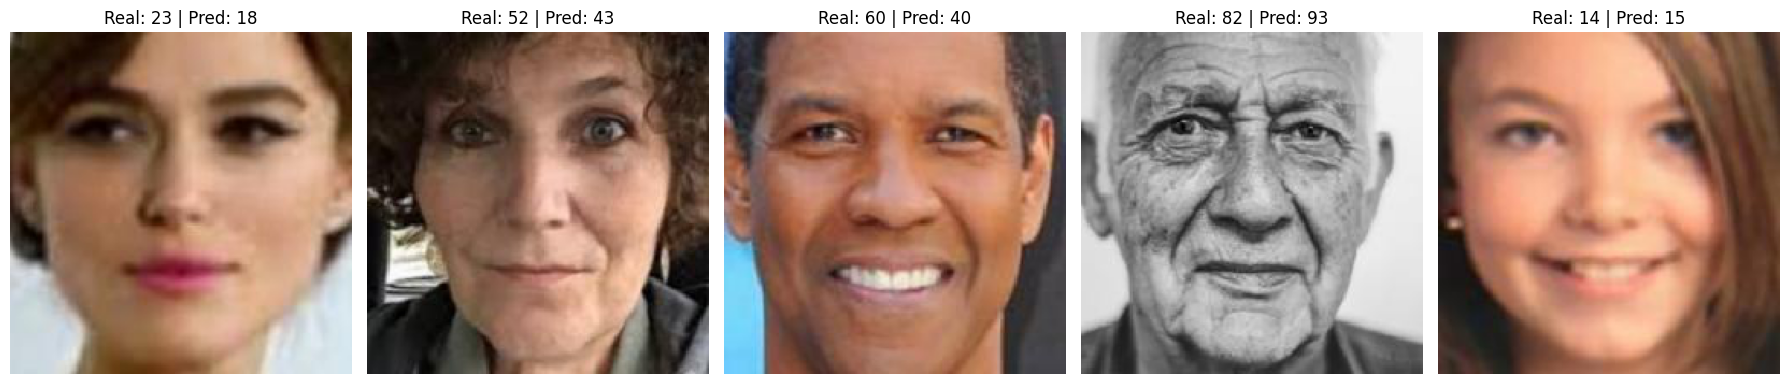

In [15]:
# Obtener un lote de imágenes y etiquetas del generador de pruebas
x_test_batch, y_test_batch = next(test_generator)

# Realizar las predicciones con el modelo
predictions = model.predict(x_test_batch)

# Configurar la visualización de 5 ejemplos redondeando las predicciones
plt.figure(figsize=(18, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test_batch[i])
    real_age = int(y_test_batch[i])
    predicted_age = int(round(float(predictions[i][0])))

    plt.title(f"Real: {real_age} | Pred: {predicted_age}")
    plt.axis('off')

plt.tight_layout()
plt.show()

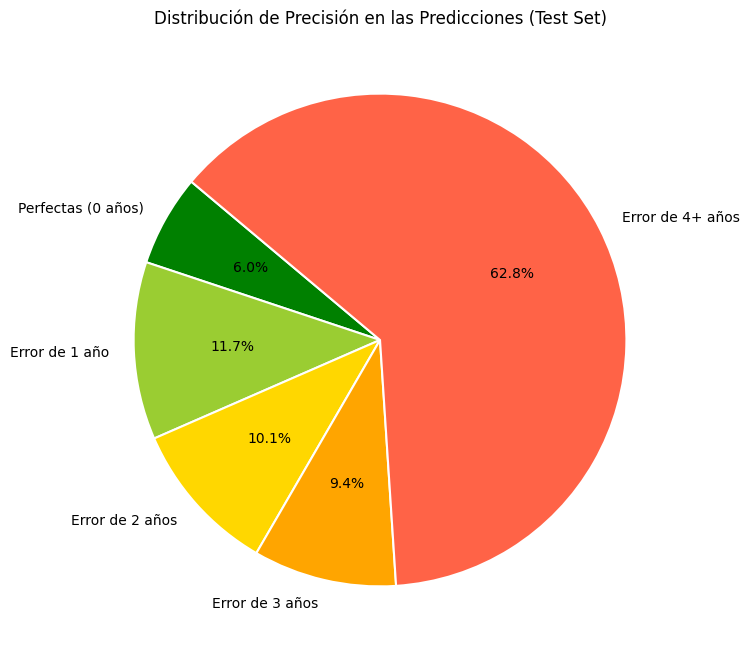

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Obtener todas las predicciones y etiquetas reales del generador de pruebas
test_generator.reset()
all_preds = []
all_real = []

# Iterar sobre todo el generador para asegurar que cubrimos todos los datos de test
for _ in range(len(test_generator)):
    x_batch, y_batch = next(test_generator)
    preds = model.predict(x_batch, verbose=0)
    all_preds.extend(preds.flatten())
    all_real.extend(y_batch)

all_preds = np.array(all_preds)
all_real = np.array(all_real)

# 2. Redondear predicciones al entero más cercano y calcular error absoluto
rounded_preds = np.round(all_preds)
diferencias = np.abs(all_real - rounded_preds)

# 3. Clasificar los errores en categorías detalladas
perfectas = np.sum(diferencias == 0)
error_1_ano = np.sum(diferencias == 1)
error_2_anos = np.sum(diferencias == 2)
error_3_anos = np.sum(diferencias == 3)
resto = np.sum(diferencias >= 4)

total = len(diferencias)

# 4. Configurar datos del gráfico de pastel
etiquetas = [
    'Perfectas (0 años)',
    'Error de 1 año',
    'Error de 2 años',
    'Error de 3 años',
    'Error de 4+ años'
]
cantidades = [perfectas, error_1_ano, error_2_anos, error_3_anos, resto]
colores = ['green', 'yellowgreen', 'gold', 'orange', 'tomato']

# 5. Dibujar la gráfica
plt.figure(figsize=(8, 8))
plt.pie(
    cantidades,
    labels=etiquetas,
    autopct='%1.1f%%',
    startangle=140,
    colors=colores,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
plt.title('Distribución de Precisión en las Predicciones (Test Set)')
plt.show()

### Visualización de Atención del Modelo con Grad-CAM

Dado que el modelo es una red convolucional residual (ResNet), podemos usar **Grad-CAM** para obtener un mapa de calor sobre las zonas del rostro que más influyeron en la predicción de la edad.

Usando la última capa convolucional encontrada: conv2d_9


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


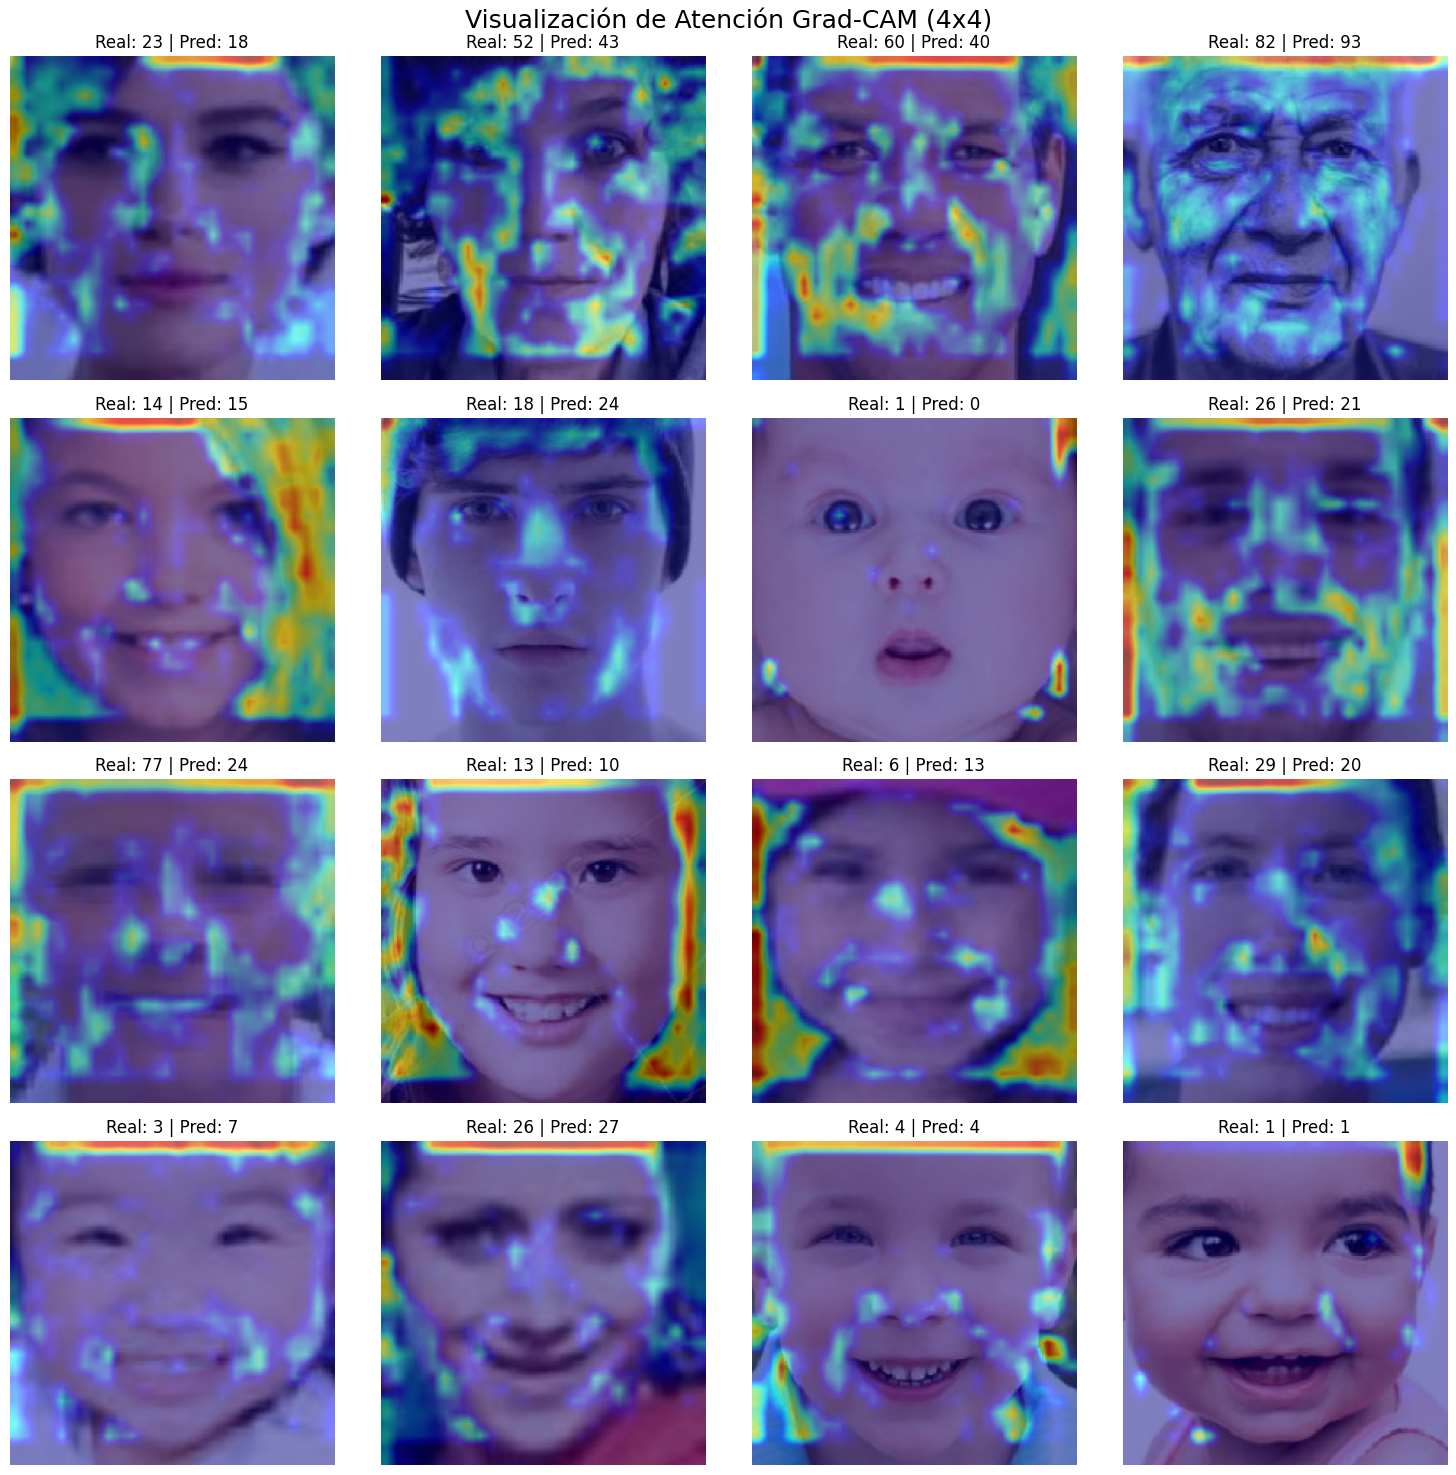

In [17]:
import tensorflow as tf
import cv2
import numpy as np
import matplotlib.pyplot as plt

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # Crear un modelo que mapee la imagen de entrada a las activaciones de la última capa convolucional
    # y a la salida de predicción del modelo
    grad_model = tf.keras.models.Model(
        inputs=[model.inputs],
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )

    # Calcular el gradiente de la predicción respecto a los mapas de características de la última capa conv
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            score = preds[:, 0]
        else:
            score = preds[:, pred_index]

    # Gradiente del valor de salida respecto al mapa de características
    grads = tape.gradient(score, last_conv_layer_output)

    # Reducir los gradientes a un vector de pesos por canal
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Multiplicar cada canal en el mapa de características por su "importancia"
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Normalizar el mapa de calor entre 0 y 1 para su visualización
    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)
    return heatmap.numpy()

def superimpose_heatmap(img, heatmap, alpha=0.4, colormap=cv2.COLORMAP_JET):
    # Reescalar el mapa de calor al tamaño de la imagen original
    heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, colormap)

    # Convertir de BGR (OpenCV) a RGB
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

    # Superponer el mapa de calor sobre la imagen original
    superimposed_img = heatmap * alpha + img * (1 - alpha)
    # Normalizar para mostrar correctamente con plt.imshow
    superimposed_img = np.clip(superimposed_img, 0, 255).astype(np.uint8)
    return superimposed_img

# Encontrar el nombre de la última capa convolucional de la arquitectura
last_conv_layer_name = None
for layer in reversed(model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_layer_name = layer.name
        break

print(f"Usando la última capa convolucional encontrada: {last_conv_layer_name}")

# Resetear e iterar el generador de pruebas para obtener suficientes imágenes
test_generator.reset()
x_test_batch, y_test_batch = next(test_generator)

# Graficar una grid de 4x4 que muestre únicamente las 16 imágenes con la atención Grad-CAM
plt.figure(figsize=(15, 15))
for i in range(16):
    img = x_test_batch[i]
    img_input = np.expand_dims(img, axis=0)

    # Generar mapa de calor
    heatmap = make_gradcam_heatmap(img_input, model, last_conv_layer_name)

    # Convertir imagen normalizada (0-1) a rango 0-255 para OpenCV
    img_255 = np.uint8(img * 255)
    gradcam_img = superimpose_heatmap(img_255, heatmap, alpha=0.5)

    real_age = int(y_test_batch[i])
    predicted_age = int(round(float(model.predict(img_input, verbose=0)[0][0])))

    # Dibujar en una cuadrícula de 4x4 sólo la visualización Grad-CAM
    plt.subplot(4, 4, i + 1)
    plt.imshow(gradcam_img)
    plt.title(f"Real: {real_age} | Pred: {predicted_age}", fontsize=12)
    plt.axis('off')

plt.suptitle("Visualización de Atención Grad-CAM (4x4)", fontsize=18, y=0.98)
plt.tight_layout()
plt.show()

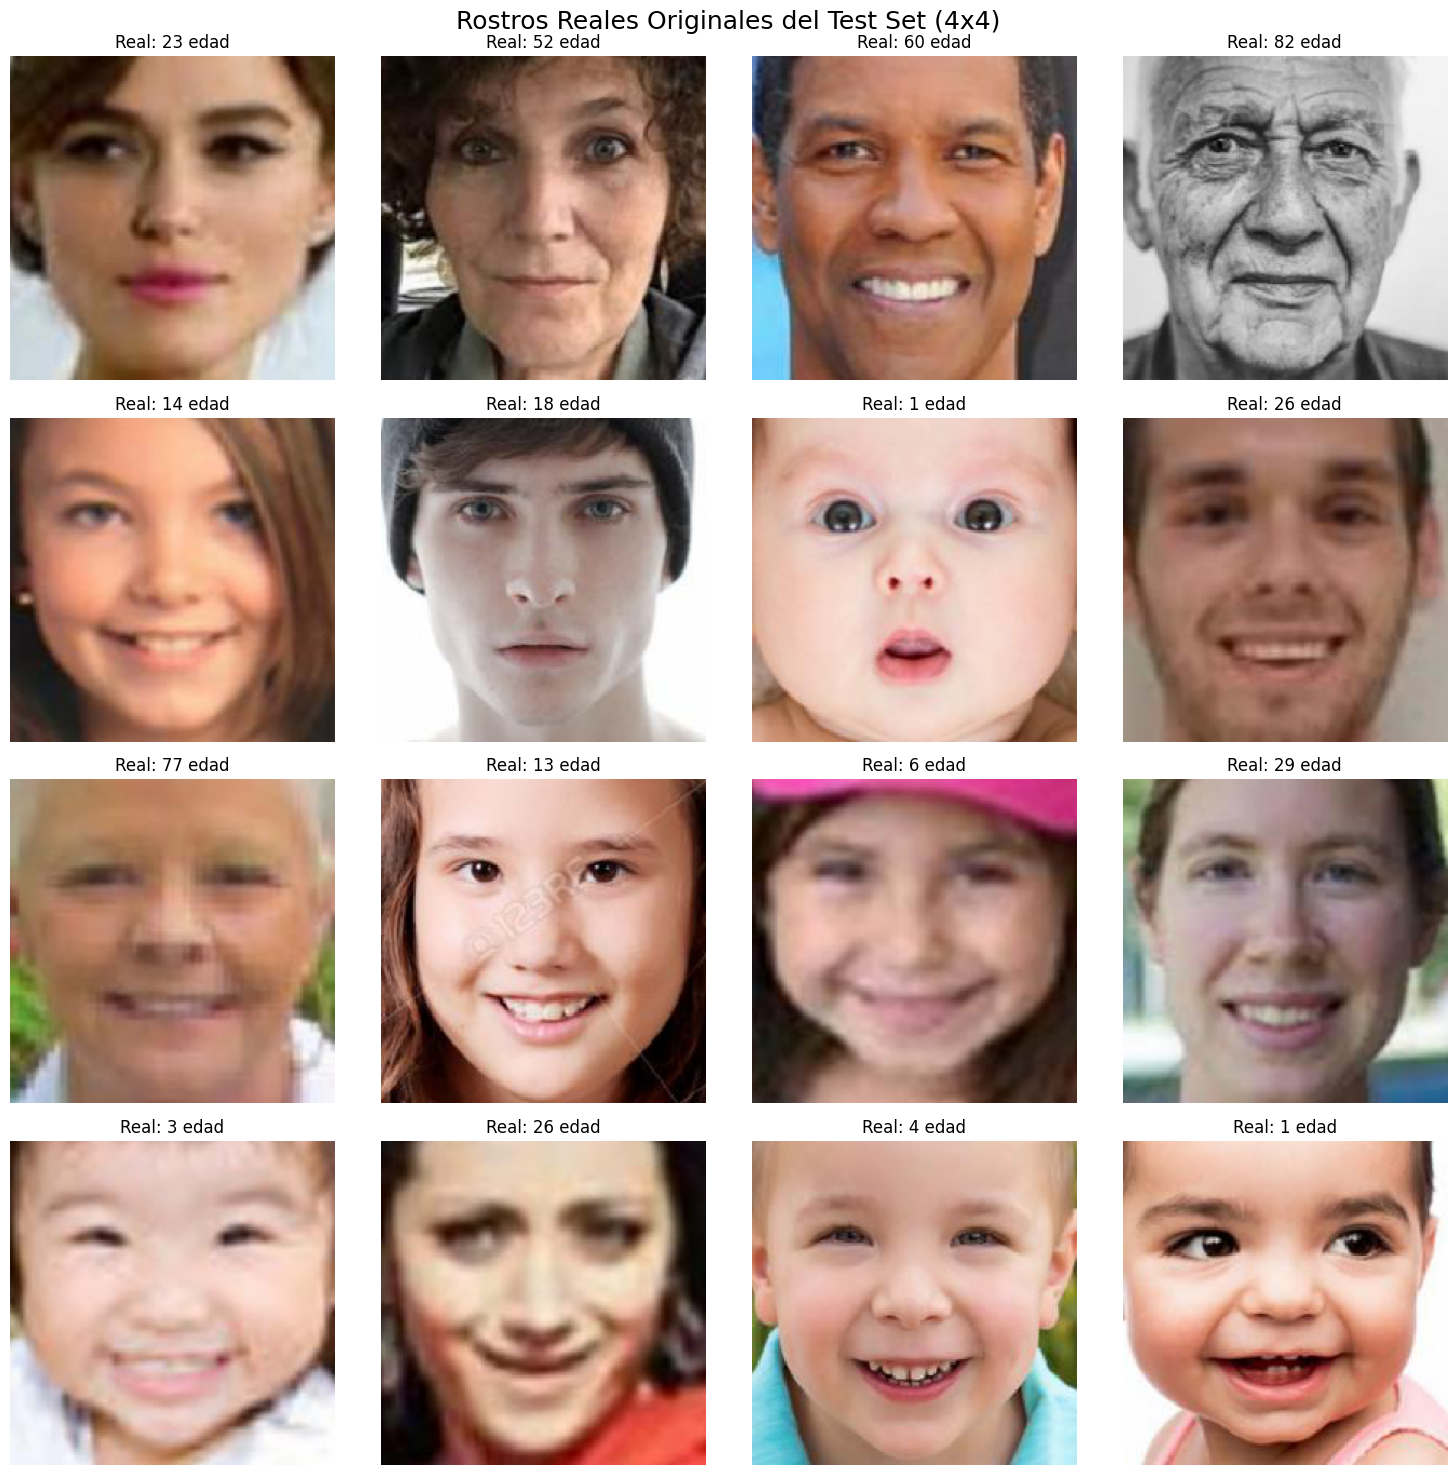

In [18]:
# Graficar una grid de 4x4 que muestre únicamente las 16 imágenes reales originales
plt.figure(figsize=(15, 15))
for i in range(16):
    img = x_test_batch[i]
    real_age = int(y_test_batch[i])

    # Dibujar la cara real original sin mapas de calor
    plt.subplot(4, 4, i + 1)
    plt.imshow(img)
    plt.title(f"Real: {real_age} edad", fontsize=12)
    plt.axis('off')

plt.suptitle("Rostros Reales Originales del Test Set (4x4)", fontsize=18, y=0.98)
plt.tight_layout()
plt.show()

# Entrega 3

Implementación de MTCNN para recortar las imagenes antes de pasarlas a la red, junto al Fine-Tunning del modelo VGGFace con sus resultados

## Función de Recorte con MTCNN
Definimos la función para procesar, recortar la cara detectada por MTCNN y redimensionar la imagen resultante a $224 \times 224$ píxeles.

In [23]:
from mtcnn import MTCNN
import numpy as np

# Create a detector instance
detector = MTCNN(device="CPU:0")

# Asegurar que la imagen esté en el formato uint8 (0-255) que MTCNN requiere
if img.dtype != np.uint8:
    if img.max() <= 1.0:
        img_uint8 = (img * 255).astype(np.uint8)
    else:
        img_uint8 = img.astype(np.uint8)
else:
    img_uint8 = img

# Detect faces in the image
result = detector.detect_faces(img_uint8)

# Display the result
print(result)

Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.


[{'box': [0, 0, 199, 223], 'confidence': np.float64(0.9797583818435669), 'keypoints': {'nose': [np.int64(114), np.int64(118)], 'mouth_right': [np.int64(152), np.int64(158)], 'right_eye': [np.int64(163), np.int64(70)], 'left_eye': [np.int64(60), np.int64(70)], 'mouth_left': [np.int64(58), np.int64(154)]}}]


In [24]:
import cv2
import numpy as np
from PIL import Image

def crop_face_mtcnn(image_path, target_size=(224, 224)):
    # Cargar la imagen usando OpenCV
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        return None

    # Convertir de BGR (OpenCV) a RGB
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # Inicializar con la imagen completa como fallback
    face_img = img_rgb

    try:
        # Detectar rostros de forma segura con MTCNN
        detections = detector.detect_faces(img_rgb)

        if len(detections) > 0:
            # Tomar la detección con mayor nivel de confianza o la más grande
            best_detection = max(detections, key=lambda item: item['box'][2] * item['box'][3])
            x, y, width, height = best_detection['box']

            # Asegurar que las coordenadas de la caja estén estrictamente dentro de los límites de la imagen
            x = max(0, int(x))
            y = max(0, int(y))
            x2 = min(img_rgb.shape[1], x + int(width))
            y2 = min(img_rgb.shape[0], y + int(height))

            # Solo recortar si las dimensiones obtenidas son coherentes y mayores a cero
            if (x2 > x) and (y2 > y):
                face_img = img_rgb[y:y2, x:x2]
    except Exception as e:
        # En caso de cualquier error interno en el detector MTCNN (ej. fallos en ONet), se usa la imagen completa
        pass

    # Convertir a objeto de imagen PIL y redimensionar
    try:
        face_pil = Image.fromarray(face_img)
        face_pil = face_pil.resize(target_size)
    except Exception as e:
        # Segundo respaldo en caso de errores de formato con PIL
        img_pil_fallback = Image.fromarray(img_rgb)
        face_pil = img_pil_fallback.resize(target_size)

    return face_pil

### Demostración del Recorte con MTCNN
Prueba de una imagen usando el recorte de MTCNN

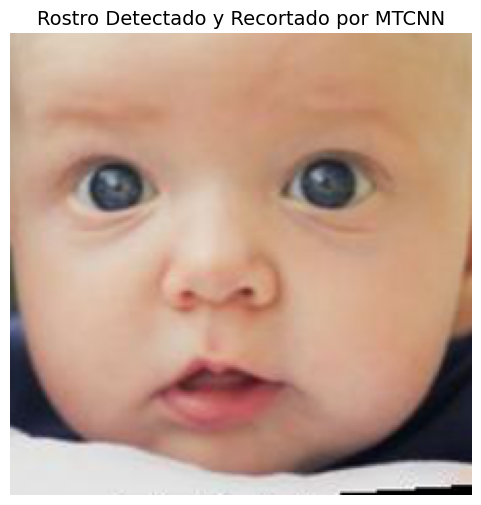

In [25]:
ejemplo_ruta = path + '001/16.png'
rostro_recortado = crop_face_mtcnn(ejemplo_ruta)

if rostro_recortado is not None:
    plt.figure(figsize=(6, 6))
    plt.imshow(rostro_recortado)
    plt.title("Rostro Detectado y Recortado por MTCNN", fontsize=14)
    plt.axis('off')
    plt.show()
else:
    print("No se pudo cargar o procesar la imagen de prueba.")

### Creación del Generador Personalizado
Implementamos un generador de secuencias de Keras que procesará las imágenes en tiempo de entrenamiento utilizando la función `crop_face_mtcnn` recién construida.

In [26]:
import tensorflow as tf

class FaceCroppedGenerator(tf.keras.utils.Sequence):
    def __init__(self, dataframe, x_col, y_col, batch_size=32, target_size=(224, 224), shuffle=True):
        self.dataframe = dataframe.reset_index(drop=True)
        self.x_col = x_col
        self.y_col = y_col
        self.batch_size = batch_size
        self.target_size = target_size
        self.shuffle = shuffle
        self.indices = np.arange(len(self.dataframe))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.dataframe) / self.batch_size))

    def __getitem__(self, index):
        batch_indices = self.indices[index * self.batch_size : (index + 1) * self.batch_size]

        batch_images = []
        batch_labels = []

        for idx in batch_indices:
            row = self.dataframe.iloc[idx]
            img_path = row[self.x_col]
            label = row[self.y_col]

            # Aplicar la detección y recorte con MTCNN
            face_pil = crop_face_mtcnn(img_path, target_size=self.target_size)

            if face_pil is not None:
                img_arr = np.array(face_pil, dtype=np.float32) / 255.0  # Normalizar píxeles a [0.0, 1.0]
                batch_images.append(img_arr)
                batch_labels.append(label)

        return np.array(batch_images), np.array(batch_labels, dtype=np.float32)

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

# Creamos los nuevos generadores con el preprocesamiento de MTCNN integrado
train_generator_cropped = FaceCroppedGenerator(train_df, x_col='filepath', y_col='age', batch_size=32, shuffle=True)
val_generator_cropped = FaceCroppedGenerator(val_df, x_col='filepath', y_col='age', batch_size=32, shuffle=False)
test_generator_cropped = FaceCroppedGenerator(test_df, x_col='filepath', y_col='age', batch_size=32, shuffle=False)

print("Generadores basados en MTCNN listos para ser entrenados.")

Generadores basados en MTCNN listos para ser entrenados.


### Preprocesamiento Completo: Recortar y Guardar en Disco

Con este código vamos a crear una nueva carpeta llamada `cropped_dataset` donde guardaremos todas las imágenes recortadas por MTCNN estructuradas por edades. De esta manera, el modelo podrá cargarlas instantáneamente durante el entrenamiento sin retrasos de CPU ni necesidad de recortarlas denuevo para pruebas de entrenamiento.

In [27]:
import os
from tqdm.notebook import tqdm

# Definir el nuevo directorio de salida para las imágenes recortadas
cropped_base_path = '/content/cropped_dataset/'
os.makedirs(cropped_base_path, exist_ok=True)

# Listas para almacenar las rutas de las nuevas imágenes procesadas de forma exitosa
cropped_file_paths = []
cropped_ages = []

print("Iniciando el proceso de recorte de todo el dataset con MTCNN...")

# Recorrer el DataFrame original y procesar cada imagen
for idx, row in tqdm(df_dataset.iterrows(), total=len(df_dataset)):
    original_path = row['filepath']
    age = row['age']

    # Crear la subcarpeta correspondiente a la edad en el nuevo directorio
    age_folder = os.path.join(cropped_base_path, f"{age:03d}")
    os.makedirs(age_folder, exist_ok=True)

    # Definir la ruta de destino de la imagen recortada
    filename = os.path.basename(original_path)
    destination_path = os.path.join(age_folder, filename)

    # Aplicar el recorte seguro con MTCNN
    cropped_img_pil = crop_face_mtcnn(original_path, target_size=(224, 224))

    if cropped_img_pil is not None:
        # Guardar la imagen recortada en disco
        cropped_img_pil.save(destination_path)
        cropped_file_paths.append(destination_path)
        cropped_ages.append(age)

# Crear un nuevo DataFrame con las rutas de las imágenes optimizadas
df_cropped_dataset = pd.DataFrame({
    'filepath': cropped_file_paths,
    'age': cropped_ages
})

print(f"Proceso finalizado. Se han procesado y guardado {len(df_cropped_dataset)} imágenes con éxito.")
display(df_cropped_dataset.head())

Iniciando el proceso de recorte de todo el dataset con MTCNN...


  0%|          | 0/9778 [00:00<?, ?it/s]

Proceso finalizado. Se han procesado y guardado 9778 imágenes con éxito.


,filepath,age
0,/content/cropped_dataset/040/6307.png,40
1,/content/cropped_dataset/040/8823.png,40
2,/content/cropped_dataset/040/1340.png,40
3,/content/cropped_dataset/040/8854.png,40
4,/content/cropped_dataset/040/3036.png,40


### Generar Nuevos Sets de Datos y Cargadores Eficientes

Ahora dividiremos nuestro dataset pre-recortado en entrenamiento

In [28]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Dividir el nuevo dataset pre-recortado (70% Train, 15% Val, 15% Test)
train_crop_df, temp_crop_df = train_test_split(df_cropped_dataset, test_size=0.3, random_state=42)
val_crop_df, test_crop_df = train_test_split(temp_crop_df, test_size=0.5, random_state=42)

# Configurar el generador que solo normaliza los píxeles (las imágenes ya están recortadas a 224x224)
fast_datagen = ImageDataGenerator(rescale=1./255)

fast_train_generator = fast_datagen.flow_from_dataframe(
    dataframe=train_crop_df,
    x_col='filepath',
    y_col='age',
    target_size=(224, 224),
    class_mode='raw',
    batch_size=32,
    shuffle=True
)

fast_val_generator = fast_datagen.flow_from_dataframe(
    dataframe=val_crop_df,
    x_col='filepath',
    y_col='age',
    target_size=(224, 224),
    class_mode='raw',
    batch_size=32,
    shuffle=False
)

fast_test_generator = fast_datagen.flow_from_dataframe(
    dataframe=test_crop_df,
    x_col='filepath',
    y_col='age',
    target_size=(224, 224),
    class_mode='raw',
    batch_size=32,
    shuffle=False
)

print("¡Nuevos generadores de alta velocidad listos!")

Found 6844 validated image filenames.
Found 1467 validated image filenames.
Found 1467 validated image filenames.
¡Nuevos generadores de alta velocidad listos!


## Implementación del modelo VGGFace

Para esta prueba, utilizaremos la librería **DeepFace**, la cual ya cuenta con modelos de redes neuronales convolucionales preentrenados y optimizados específicamente para la predicción de edad en rostros humanos.

In [19]:
pip install deepface

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 51.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.4/73.4 MB 40.0 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [deepface]


In [20]:
from deepface import DeepFace
# Cargar el modelo base VGG-Face de manera correcta usando la API de DeepFace
model3 = DeepFace.build_model("VGG-Face")
print("¡Modelo VGG-Face cargado exitosamente en model3!")

26-11-18 01:59:14 - Directory /root/.deepface has been created
26-11-18 01:59:14 - Directory /root/.deepface/weights has been created
26-11-18 01:59:15 - 🔗 vgg_face_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/vgg_face_weights.h5 to /root/.deepface/weights/vgg_face_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/vgg_face_weights.h5
To: /root/.deepface/weights/vgg_face_weights.h5
100%|██████████| 580M/580M [01:00<00:00, 9.66MB/s]


¡Modelo VGG-Face cargado exitosamente en model3!


### Fine-Tuning de VGG-Face (model3) para Regresión de Edad

Adaptamos la arquitectura base de VGG-Face congelando sus capas convolucionales inferiores y agregando una cabeza densa de regresión optimizada para estimar la edad en base a los embeddings del rostro.

In [21]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten, Dropout, Input
from tensorflow.keras.callbacks import ModelCheckpoint

# 1. Obtener la arquitectura Keras interna de VGG-Face
base_vgg = model3.model

# Congelar las capas iniciales (80% del modelo base)
num_layers_to_freeze = int(len(base_vgg.layers) * 0.8)
for layer in base_vgg.layers[:num_layers_to_freeze]:
    layer.trainable = False
for layer in base_vgg.layers[num_layers_to_freeze:]:
    layer.trainable = True

# 2. Agregar una cabeza de regresión secuencial utilizando la salida del modelo base
# Usamos la penúltima o última capa de representación
x = base_vgg.output
if len(x.shape) > 2:
    x = Flatten()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.4)(x)
output_layer = Dense(1, activation='linear')(x)

# Crear el modelo final adaptado para regresión de edad
model3_fine_tuned = Model(inputs=base_vgg.input, outputs=output_layer)

# 3. Compilar el modelo con una tasa de aprendizaje baja para fine-tuning seguro
model3_fine_tuned.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='mean_squared_error',
    metrics=['mean_absolute_error']
)

print("¡Modelo VGG-Face adaptado y compilado con éxito para regresión!")

¡Modelo VGG-Face adaptado y compilado con éxito para regresión!


In [29]:
# 4. Entrenar por 15 épocas usando los generadores optimizados
checkpointer_vgg = ModelCheckpoint(
    'vgg_face_finetuned.keras',
    monitor='val_loss',
    mode='min',
    save_best_only=True,
    verbose=1
)

history_vgg = model3_fine_tuned.fit(
    fast_train_generator,
    validation_data=fast_val_generator,
    epochs=15,
    callbacks=[checkpointer_vgg, lr_reducer, early_stopping]
)

Epoch 1/15
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 472ms/step - loss: 497.4704 - mean_absolute_error: 15.4884
Epoch 1: val_loss improved from None to 83.59603, saving model to vgg_face_finetuned.keras

Epoch 1: finished saving model to vgg_face_finetuned.keras
214/214 ━━━━━━━━━━━━━━━━━━━━ 188s 700ms/step - loss: 258.5075 - mean_absolute_error: 10.8468 - val_loss: 83.5960 - val_mean_absolute_error: 6.2718 - learning_rate: 1.0000e-04
Epoch 2/15
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 237ms/step - loss: 106.8210 - mean_absolute_error: 7.1169
Epoch 2: val_loss improved from 83.59603 to 74.56124, saving model to vgg_face_finetuned.keras

Epoch 2: finished saving model to vgg_face_finetuned.keras
214/214 ━━━━━━━━━━━━━━━━━━━━ 97s 375ms/step - loss: 103.1985 - mean_absolute_error: 6.9068 - val_loss: 74.5612 - val_mean_absolute_error: 5.6462 - learning_rate: 1.0000e-04
Epoch 3/15
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 237ms/step - loss: 87.9001 - mean_absolute_error: 6.3613
Epoch 3: val_loss improved from 74.56124 to

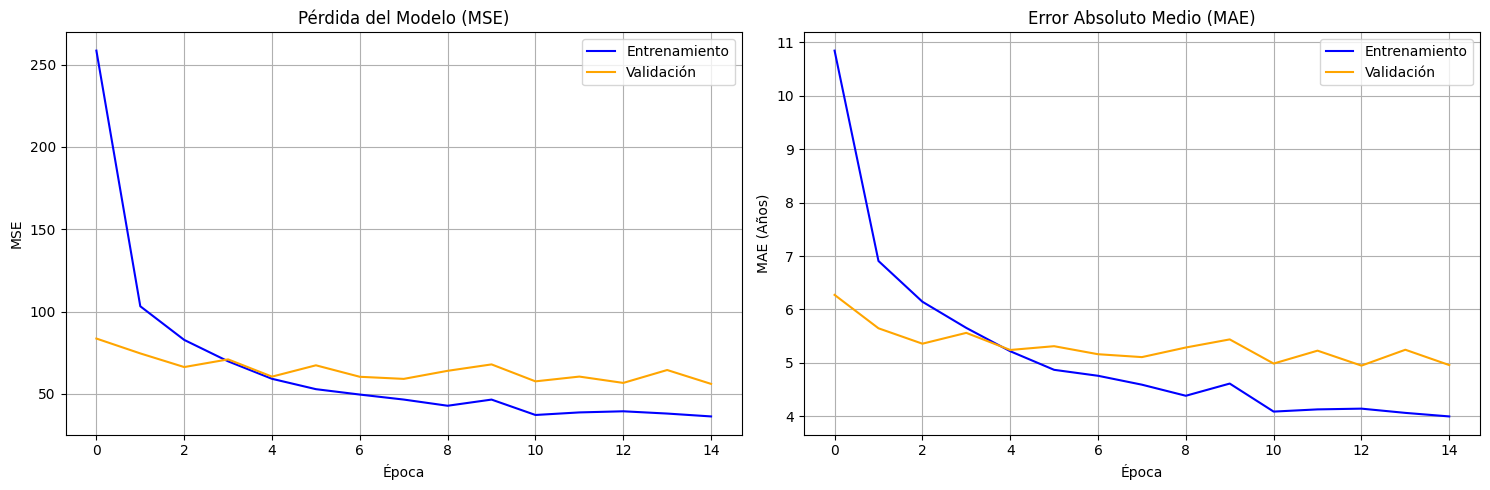

In [30]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico de Pérdida (MSE)
ax1.plot(history_vgg.history['loss'], label='Entrenamiento', color='blue')
ax1.plot(history_vgg.history['val_loss'], label='Validación', color='orange')
ax1.set_title('Pérdida del Modelo (MSE)')
ax1.set_xlabel('Época')
ax1.set_ylabel('MSE')
ax1.legend()
ax1.grid(True)

# Gráfico de MAE (Error Medio Absoluto)
ax2.plot(history_vgg.history['mean_absolute_error'], label='Entrenamiento', color='blue')
ax2.plot(history_vgg.history['val_mean_absolute_error'], label='Validación', color='orange')
ax2.set_title('Error Absoluto Medio (MAE)')
ax2.set_xlabel('Época')
ax2.set_ylabel('MAE (Años)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

In [31]:
# Reemplazamos el modelo interno del cliente para que la celda de testeo posterior use el modelo entrenado
model3.model = model3_fine_tuned
print("model3 actualizado con los pesos del Fine-Tuning.")

model3 actualizado con los pesos del Fine-Tuning.


In [32]:
# Mostrar el resumen estructural de las capas de model3
model3.model.summary()

Model: "functional_56"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d (ZeroPadding2D)  │ (None, 226, 226, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d_1                │ (None, 226, 226, 64)   │             0 │
│ (ZeroPadding2D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d_2                │ (None, 114, 114, 64)   │             0 │
│ (ZeroPadding2D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d_3                │ (None, 114, 114, 128)  │             0 │
│ (ZeroPadding2D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d_4                │ (None, 58, 58, 128)    │             0 │
│ (ZeroPadding2D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d_5                │ (None, 58, 58, 256)    │             0 │
│ (ZeroPadding2D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d_6                │ (None, 58, 58, 256)    │             0 │
│ (ZeroPadding2D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d_7                │ (None, 30, 30, 256)    │             0 │
│ (ZeroPadding2D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d_8                │ (None, 30, 30, 512)    │             0 │
│ (ZeroPadding2D)                 │                        │             

 Total params: 384,365,125 (1.43 GB)

 Trainable params: 124,790,017 (476.04 MB)

 Non-trainable params: 9,995,072 (38.13 MB)

 Optimizer params: 249,580,036 (952.07 MB)

## Evaluación con el Conjunto de Prueba
Evaluamos el modelo de VGGFace con datos del conjunto de test para calcular los errores de predicción y obtener resultados.

In [33]:
import numpy as np

all_real_ages = []
all_pred_ages = []

# Reiniciar el generador para asegurar consistencia
fast_test_generator.reset()

print("Evaluando el modelo VGG-Face ajustado con el test_generator...")
for i in range(len(fast_test_generator)):
    x_batch, y_batch = next(fast_test_generator)

    # Predecir con el modelo optimizado
    preds = model3.model.predict(x_batch, verbose=0)
    pred_flat = preds.flatten()

    all_pred_ages.extend(pred_flat)
    all_real_ages.extend(y_batch)

all_real_ages = np.array(all_real_ages)
all_pred_ages = np.array(all_pred_ages)

# Calcular métricas definitivas de prueba
test_loss = np.mean((all_real_ages - all_pred_ages) ** 2) # MSE
test_mae = np.mean(np.abs(all_real_ages - all_pred_ages))  # MAE

print(f"\nPérdida (MSE) en Test: {test_loss:.4f}")
print(f"Error Absoluto Medio (MAE) en Test: {round(test_mae, 1)} años")

Evaluando el modelo VGG-Face ajustado con el test_generator...

Pérdida (MSE) en Test: 63.6805
Error Absoluto Medio (MAE) en Test: 5.0 años


### Distribución de Precisión de Predicciones para model3 (VGG-Face)

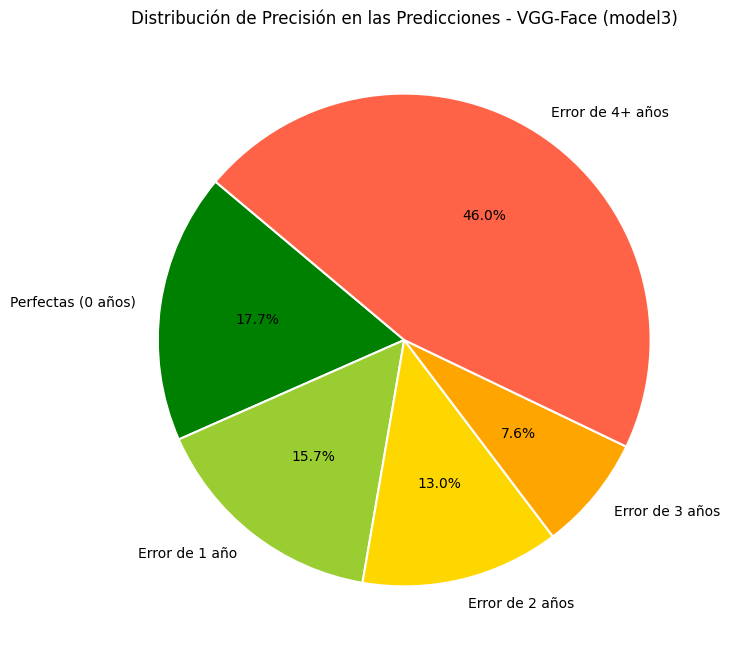

In [34]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Obtener todas las predicciones y etiquetas reales del generador de pruebas para model3
fast_test_generator.reset()
all_preds_vgg = []
all_real_vgg = []

for _ in range(len(fast_test_generator)):
    x_batch, y_batch = next(fast_test_generator)
    # Usamos model3.model para predecir
    preds = model3.model.predict(x_batch, verbose=0)
    all_preds_vgg.extend(preds.flatten())
    all_real_vgg.extend(y_batch)

all_preds_vgg = np.array(all_preds_vgg)
all_real_vgg = np.array(all_real_vgg)

# 2. Redondear predicciones al entero más cercano y calcular error absoluto
rounded_preds_vgg = np.round(all_preds_vgg)
diferencias_vgg = np.abs(all_real_vgg - rounded_preds_vgg)

# 3. Clasificar los errores en categorías
perfectas_vgg = np.sum(diferencias_vgg == 0)
error_1_ano_vgg = np.sum(diferencias_vgg == 1)
error_2_anos_vgg = np.sum(diferencias_vgg == 2)
error_3_anos_vgg = np.sum(diferencias_vgg == 3)
resto_vgg = np.sum(diferencias_vgg >= 4)

# 4. Configurar datos del gráfico de pastel
etiquetas_vgg = [
    'Perfectas (0 años)',
    'Error de 1 año',
    'Error de 2 años',
    'Error de 3 años',
    'Error de 4+ años'
]
cantidades_vgg = [perfectas_vgg, error_1_ano_vgg, error_2_anos_vgg, error_3_anos_vgg, resto_vgg]
colores_vgg = ['green', 'yellowgreen', 'gold', 'orange', 'tomato']

# 5. Dibujar la gráfica
plt.figure(figsize=(8, 8))
plt.pie(
    cantidades_vgg,
    labels=etiquetas_vgg,
    autopct='%1.1f%%',
    startangle=140,
    colors=colores_vgg,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
plt.title('Distribución de Precisión en las Predicciones - VGG-Face (model3)')
plt.show()

### Visualización mapas de calor

No funcionó Grad-Cam, generó unicamente caras rojas o azuladas sin mapas de calor visibles, los mapas de calor se crearon de una forma diferente, solo con la magnitud de activación de la capa convolucional, para la capa 22 ya que la 23 y la 24 tenían problemas de verse azules o rojas igualmente.

Lastimosamente los mapas de calor reportados en la tercera entrega se perdierón por accidentalemente volver a ejecutar todas las celdas, lo que los borró

In [48]:
def get_direct_activation_heatmap(img_array, model, conv_layer_name):
    """Genera un mapa de calor basado únicamente en la magnitud de activación de la capa convolucional."""
    # Crear un modelo que devuelva la salida de la capa convolucional deseada
    activation_model = tf.keras.models.Model(
        inputs=[model.input],
        outputs=[model.get_layer(conv_layer_name).output]
    )

    # Obtener las activaciones mediante una propagación hacia adelante
    activations = activation_model(img_array) # Forma: (1, H_feature, W_feature, Canales)
    activations_val = activations[0]          # Forma: (H_feature, W_feature, Canales)

    # Promediar todos los canales de activación para reducir a un mapa 2D
    heatmap = tf.reduce_mean(activations_val, axis=-1)

    # Aplicar ReLU para enfocarnos en estímulos positivos
    heatmap = tf.maximum(heatmap, 0.0)

    # Normalizar el mapa de calor de forma estable entre 0 y 1
    max_val = tf.reduce_max(heatmap)
    if max_val > 0.0:
        heatmap = heatmap / max_val

    return heatmap.numpy()

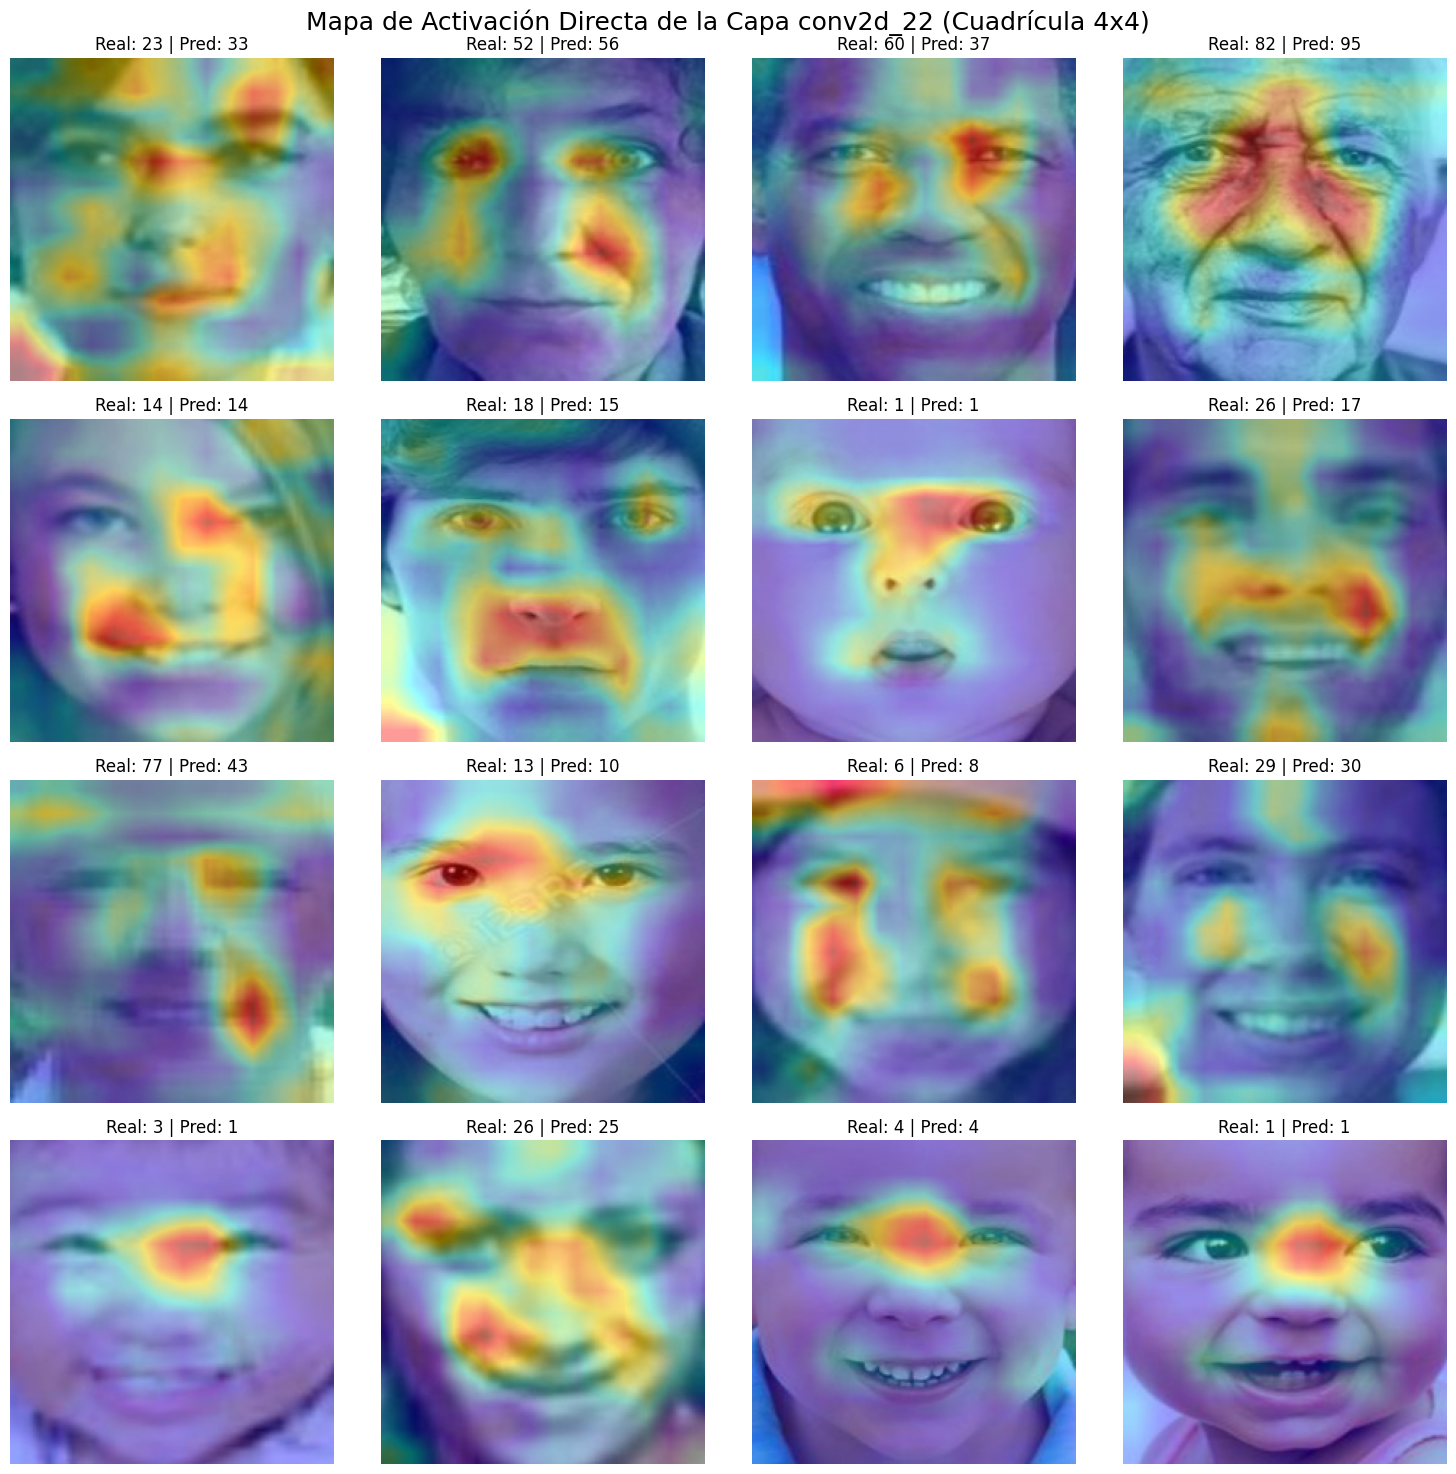

In [50]:
# Resetear el generador de pruebas para consistencia
fast_test_generator.reset()
x_test_batch_grid, y_test_batch_grid = next(fast_test_generator)

target_activation_layer = 'conv2d_22'

plt.figure(figsize=(15, 15))

for i in range(16):
    img = x_test_batch_grid[i]
    img_input = np.expand_dims(img, axis=0)

    # Generar el mapa de calor de activación directa para la capa seleccionada
    heatmap = get_direct_activation_heatmap(img_input, model3.model, target_activation_layer)

    # Asegurar la forma correcta para la superposición
    heatmap_np = np.array(heatmap, dtype=np.float32)
    if len(heatmap_np.shape) > 2:
        heatmap_np = np.mean(heatmap_np, axis=-1)

    # Convertir la imagen de prueba a rango [0-255] para OpenCV
    img_255 = np.uint8(img * 255)
    activation_grid_img = superimpose_heatmap_safe(img_255, heatmap_np, alpha=0.4)

    real_age = int(y_test_batch_grid[i])
    predicted_age = int(round(float(model3.model.predict(img_input, verbose=0)[0][0])))

    # Graficar en la cuadrícula de 4x4
    plt.subplot(4, 4, i + 1)
    plt.imshow(activation_grid_img)
    plt.title(f"Real: {real_age} | Pred: {predicted_age}", fontsize=12)
    plt.axis('off')

plt.suptitle(f"Mapa de Activación Directa de la Capa {target_activation_layer} (Cuadrícula 4x4)", fontsize=18, y=0.98)
plt.tight_layout()
plt.show()